# Demo 3 Linear Classification and Distribution Geometry

Lecture slide 33. Compare logistic regression and LDA, then explore standardization and Mahalanobis distance.

**How to use in Google Colab**
1. Upload this `.ipynb` using **File → Upload notebook**.
2. Select **Runtime → Run all**. A CPU runtime is sufficient.
3. Read the default figures, then move the sliders. Release a slider to redraw.

All figures and controls use English. All datasets are generated locally with fixed random seeds.
Changing a control never requires uploading a file. If a widget is unavailable, edit the
arguments of the corresponding `..._view(...)` call and rerun that cell.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.special import expit
from IPython.display import display
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # Also runs in a standard Jupyter environment.

BLUE, ORANGE, TEAL, NAVY = '#1479e8', '#ff8a20', '#079f9f', '#10264e'
COLORS = [BLUE, ORANGE, TEAL]
REGIONS = ListedColormap(['#dfedff', '#ffe8d5', '#d7f3ef'])
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.labelcolor':NAVY,
                     'axes.titlesize':12, 'figure.constrained_layout.use':True})

def slider(value, low, high, step, label):
    return widgets.FloatSlider(value=value, min=low, max=high, step=step,
                               description=label, continuous_update=False,
                               style={'description_width':'initial'})

def integer(value, low, high, label, step=1):
    return widgets.IntSlider(value=value, min=low, max=high, step=step,
                             description=label, continuous_update=False,
                             style={'description_width':'initial'})

def controls(fn, **kwargs):
    # Release the slider to redraw. A normal static example is shown above each control.
    panel = widgets.interactive(fn, **kwargs)
    display(panel)
    return panel

def class_points(ax, X, y, alpha=1, size=26):
    for k in np.unique(y):
        ax.scatter(*X[y==k].T, c=COLORS[int(k)], s=size, alpha=alpha,
                   edgecolors='white', linewidths=.4, label=['P','Q','R'][int(k)])

def mesh(X, n=150, pad=.7):
    lo, hi = X.min(axis=0)-pad, X.max(axis=0)+pad
    gx, gy = np.meshgrid(np.linspace(lo[0],hi[0],n), np.linspace(lo[1],hi[1],n))
    return gx, gy, np.c_[gx.ravel(),gy.ravel()]

print('Ready. CPU is sufficient. No external datasets are required.')

Ready. CPU is sufficient. No external datasets are required.


## 1 Compare the assumptions behind the boundaries
Logistic regression models $p(C\mid x)$ directly. LDA models Gaussian class distributions
with a **shared covariance matrix**, together with the class priors.
QDA is included as a contrast: it permits a different covariance matrix for each class,
and its decision boundary is generally **quadratic**, not linear.

Choose shared or unequal generating covariances. The controls regenerate reproducible
training and validation samples. Models only see the training split.
Ellipses show two-standard-deviation contours of each **generating** class distribution.
Neither method is guaranteed to win on every finite sample.

Blue = P; orange = Q. Probability shading shows p(Q | x).
The validation samples are independent draws from the same generating distributions.


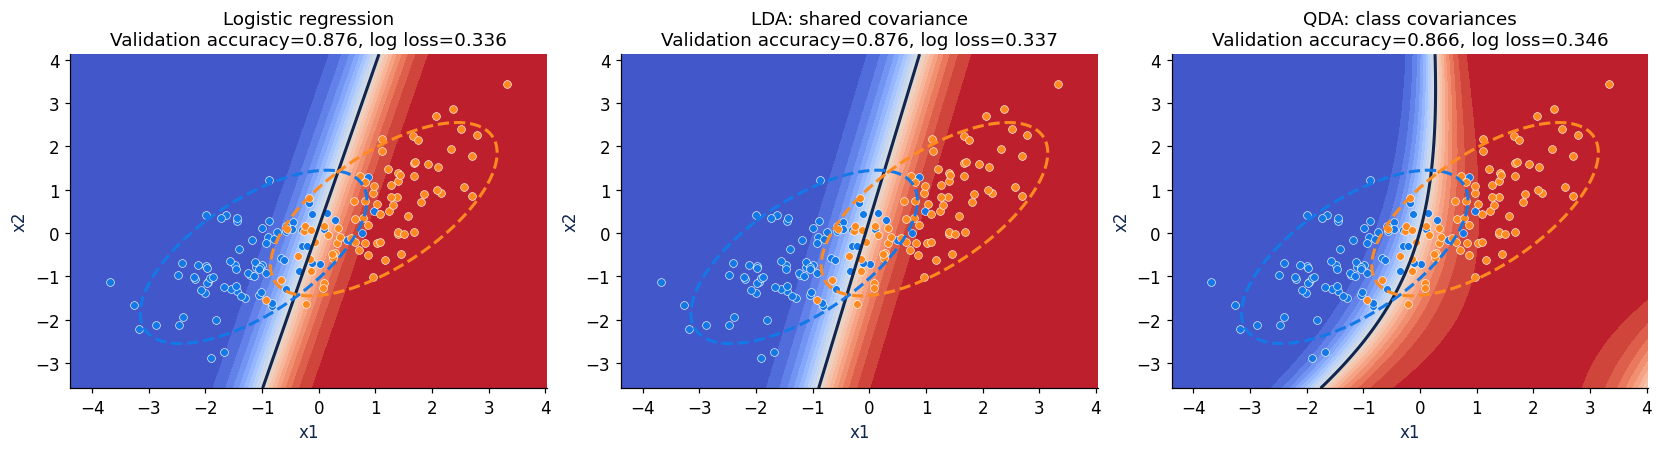

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss

def gaussian_data(scenario='Shared covariance', n=80, correlation=.65):
    rng=np.random.default_rng(31)
    means=[np.array([-1.15,-.55]),np.array([1.15,.55])]
    S0=np.array([[1,correlation],[correlation,1.]])
    S1=S0.copy() if scenario=='Shared covariance' else np.array([[.35,-.45*correlation],[-.45*correlation,1.6]])
    covs=[S0,S1]
    X=np.concatenate([rng.multivariate_normal(mu,S,n) for mu,S in zip(means,covs)])
    y=np.repeat([0,1],n)
    Xv=np.concatenate([rng.multivariate_normal(mu,S,250) for mu,S in zip(means,covs)])
    yv=np.repeat([0,1],250)
    return X,y,Xv,yv,means,covs

def ellipse_points(mu,S,radius=2):
    lam,U=np.linalg.eigh(S);t=np.linspace(0,2*np.pi,240)
    return mu[:,None]+U@(np.sqrt(lam)[:,None]*radius*np.array([np.cos(t),np.sin(t)]))

def model_comparison_view(scenario='Shared covariance',n_per_class=80,correlation=.65):
    X,y,Xv,yv,means,covs=gaussian_data(scenario,n_per_class,correlation)
    models=[make_pipeline(StandardScaler(),LogisticRegression(C=1e4,max_iter=2000)),
            LinearDiscriminantAnalysis(),QuadraticDiscriminantAnalysis(reg_param=0)]
    gx,gy,G=mesh(X)
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    for ax,name,model in zip(axs,['Logistic regression','LDA: shared covariance','QDA: class covariances'],models):
        model.fit(X,y);pr=model.predict_proba(G)[:,1].reshape(gx.shape)
        ax.contourf(gx,gy,pr,levels=np.linspace(0,1,21),cmap='coolwarm',vmin=0,vmax=1)
        if pr.min()<.5<pr.max():ax.contour(gx,gy,pr,levels=[.5],colors=NAVY,linewidths=2)
        class_points(ax,X,y)
        for k in range(2):ax.plot(*ellipse_points(means[k],covs[k]),c=COLORS[k],lw=2,ls='--')
        acc=accuracy_score(yv,model.predict(Xv));ce=log_loss(yv,model.predict_proba(Xv),labels=[0,1])
        ax.set(xlabel='x1',ylabel='x2',title=f'{name}\nValidation accuracy={acc:.3f}, log loss={ce:.3f}')
    plt.show()
    print('Blue = P; orange = Q. Probability shading shows p(Q | x).')
    print('The validation samples are independent draws from the same generating distributions.')

model_comparison_view()

Blue = P; orange = Q. Probability shading shows p(Q | x).
The validation samples are independent draws from the same generating distributions.


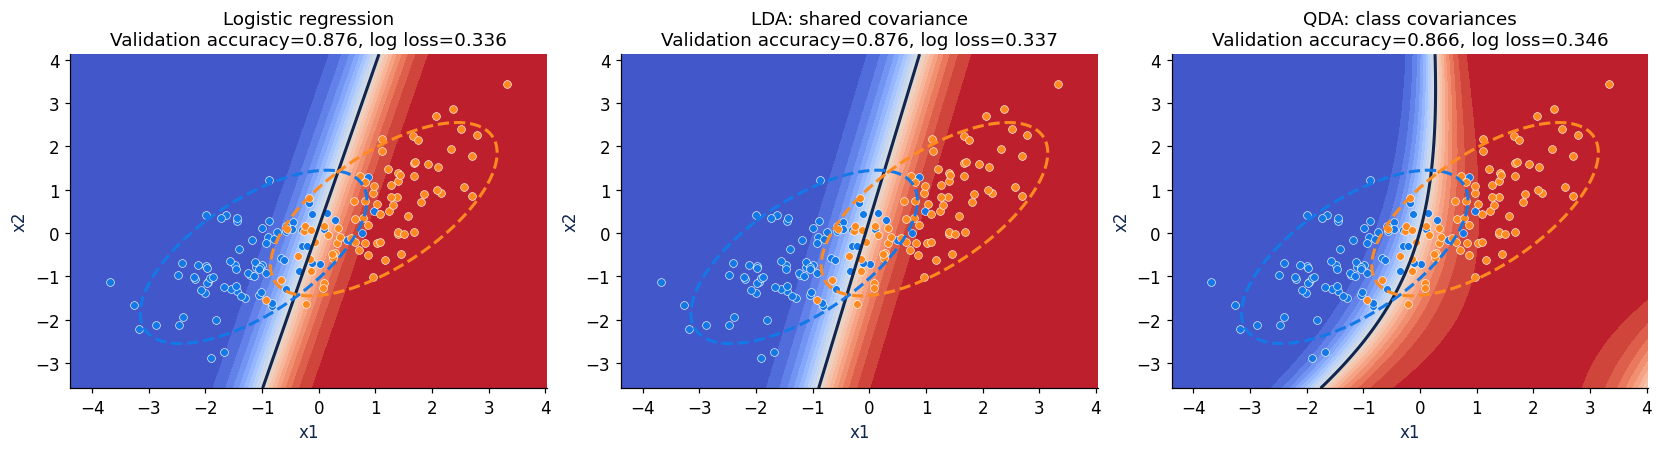

interactive(children=(Dropdown(description='Generating distribution', options=('Shared covariance', 'Unequal c…

In [6]:
comparison_controls=controls(model_comparison_view,
    scenario=widgets.Dropdown(options=['Shared covariance','Unequal covariance'],description='Generating distribution',style={'description_width':'initial'}),
    n_per_class=integer(80,15,160,'Training samples / class',5),
    correlation=slider(.65,-.85,.85,.05,'Correlation parameter'))

## 2 Standardization changes optimization geometry
Standardization uses $z_j=(x_j-\mu_j)/\sigma_j$ with statistics fitted on the training data.
It does **not** remove correlation, make the data Gaussian, or assign equal importance to features.

In this controlled example, the centered data contain paired observations $(x,t)$ and
$(-x,1-t)$. This symmetry permits an intercept of zero. We train a logistic model with two
weights and **no regularization**, so an invertible change of units does not change the
available probability functions. We compare a fixed number of gradient updates, not fully
converged solutions.

The first feature's units are multiplied by a chosen factor. Both versions are centered;
only the standardized version also divides by the standard deviation. Each uses its own
conservative learning rate $\eta=0.9/L_{bound}$, where
$L_{bound}=\lambda_{max}(X^TX)/(4N)$ bounds the curvature of logistic loss.
Large differences in scale can still make the unscaled optimization much slower.

Correlation before/after: 0.691 / 0.691
Unscaled: learning rate 0.00041, loss 0.4373
Standardized: learning rate 2.13, loss 0.4134
Scaling does not make a feature intrinsically more or less informative.


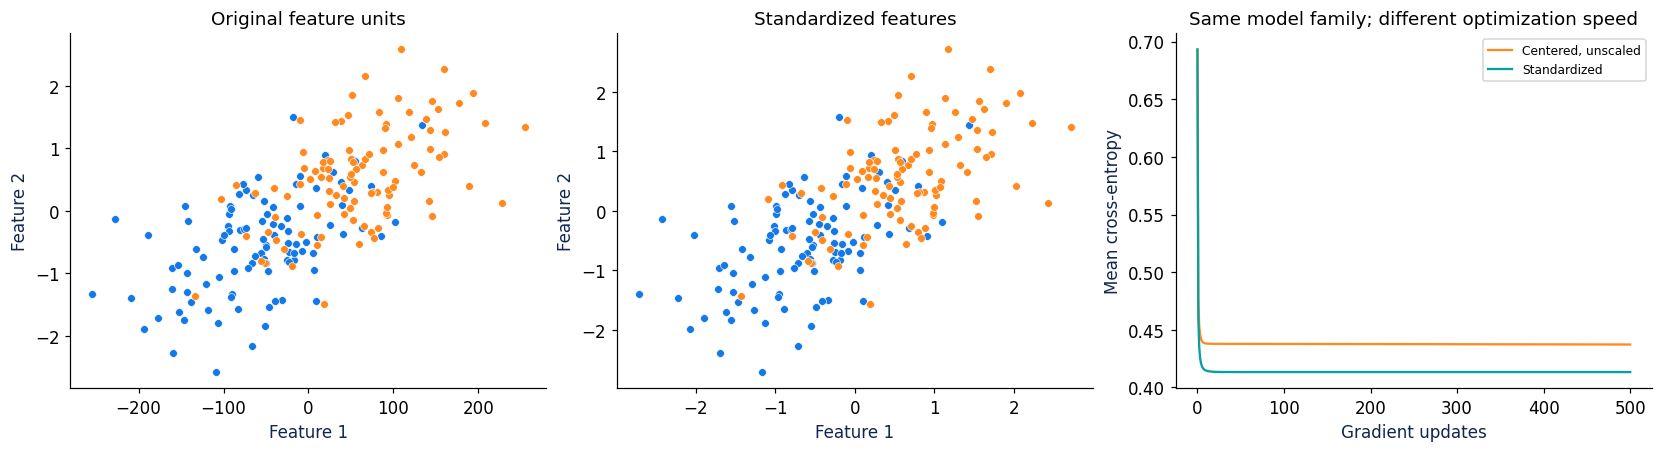

In [8]:
rng_scale=np.random.default_rng(11)
half_X=rng_scale.multivariate_normal([0,0],[[1,.65],[.65,1]],100)
half_t=rng_scale.binomial(1,expit(1.1*half_X[:,0]+.9*half_X[:,1]))
X_units=np.r_[half_X,-half_X]
t_units=np.r_[half_t,1-half_t]

def logistic_gd_no_intercept(X,t,steps=500):
    bound=np.linalg.eigvalsh(X.T@X/(4*len(X))).max()
    eta=.9/bound;w=np.zeros(X.shape[1]);losses=[]
    for step in range(steps+1):
        s=X@w;losses.append(np.mean(np.logaddexp(0,s)-t*s))
        if step<steps:w-=eta*(X.T@(expit(s)-t)/len(X))
    return w,np.array(losses),eta

def standardization_view(unit_factor=100,updates=500):
    X=X_units*np.array([float(unit_factor),1.])
    scaler=StandardScaler().fit(X);Z=scaler.transform(X)
    # Centering alone separates the effect of scaling from the effect of a large mean.
    Xc=X-scaler.mean_
    wr,lr,er=logistic_gd_no_intercept(Xc,t_units,updates)
    wz,lz,ez=logistic_gd_no_intercept(Z,t_units,updates)
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    for ax,A,title in zip(axs[:2],[X,Z],['Original feature units','Standardized features']):
        class_points(ax,A,t_units)
        ax.set(xlabel='Feature 1',ylabel='Feature 2',title=title)
    axs[2].plot(lr,c=ORANGE,label='Centered, unscaled')
    axs[2].plot(lz,c=TEAL,label='Standardized')
    axs[2].set(xlabel='Gradient updates',ylabel='Mean cross-entropy',title='Same model family; different optimization speed')
    axs[2].legend(fontsize=8);plt.show()
    print(f'Correlation before/after: {np.corrcoef(X.T)[0,1]:.3f} / {np.corrcoef(Z.T)[0,1]:.3f}')
    print(f'Unscaled: learning rate {er:.3g}, loss {lr[-1]:.4f}')
    print(f'Standardized: learning rate {ez:.3g}, loss {lz[-1]:.4f}')
    print('Scaling does not make a feature intrinsically more or less informative.')

standardization_view()

Correlation before/after: 0.691 / 0.691
Unscaled: learning rate 0.00041, loss 0.4373
Standardized: learning rate 2.13, loss 0.4134
Scaling does not make a feature intrinsically more or less informative.


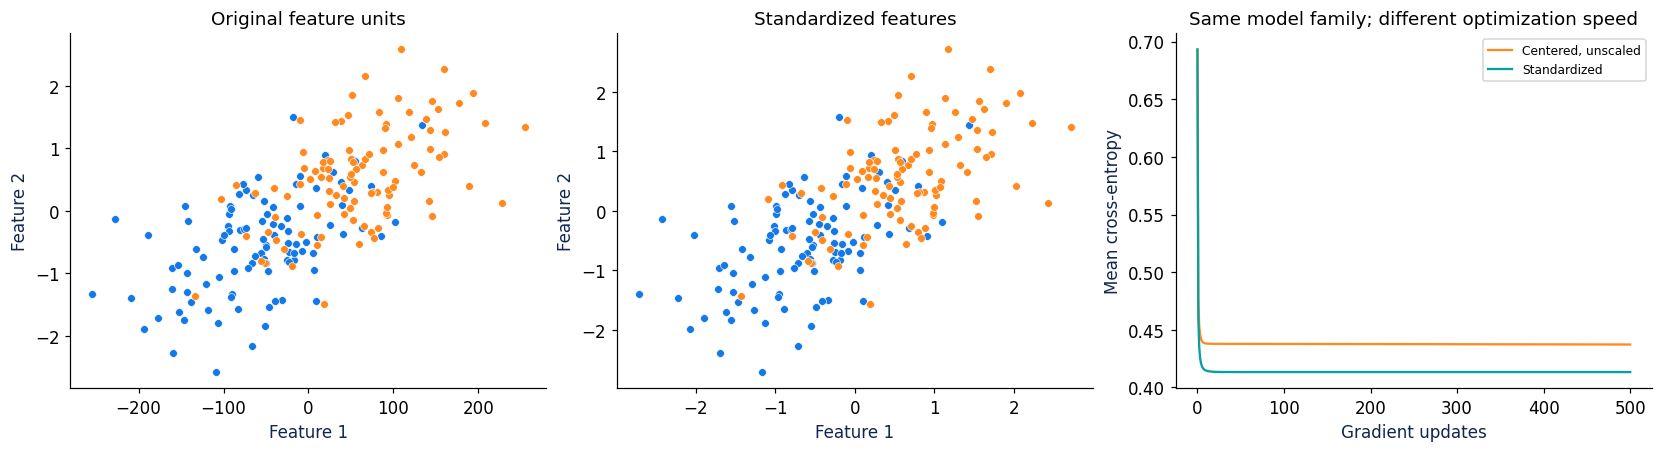

interactive(children=(Dropdown(description='Feature 1 unit factor', index=2, options=(1, 10, 100, 1000), style…

In [9]:
scale_controls=controls(standardization_view,
    unit_factor=widgets.Dropdown(options=[1,10,100,1000],value=100,description='Feature 1 unit factor',style={'description_width':'initial'}),
    updates=integer(500,50,1500,'Updates',50))

## 3 Mahalanobis distance and whitening
For class $k$,
$d_k^2(x)=(x-\mu_k)^T\Sigma_k^{-1}(x-\mu_k)$.
Write $\Sigma_k=U_k\Lambda_kU_k^T$ and whiten with
$u=\Lambda_k^{-1/2}U_k^T(x-\mu_k)$. Then $d_k(x)=\|u\|_2$.

The long principal axis maps to $u_1$, and the short principal axis maps to $u_2$.
Reference point A has distance 1 along the long axis; B has distance 2 along the short axis.
Their transformed locations are **A=(1,0)** and **B=(0,2)**, not points on the same ray.

Move the black query point. Compute its distance using **each class's ruler**, because its
class is unknown. Gaussian classification also uses covariance volume and class priors:

$$g_k(x)=-\tfrac12\left[d_k^2(x)+\log|\Sigma_k|\right]+\log\pi_k.$$

Shared covariance yields an LDA-type linear rule; class-specific covariance generally yields a
QDA-type rule. The ruler setting below uses either estimate on the same fixed data, generated
with unequal covariances. It changes the assumed model, not the dataset.

With a shared covariance ruler, the ellipses and circles describe the **assumed model covariance**. A particular class's empirical cloud need not become spherical if that shared-covariance assumption is inaccurate.

Query squared distances [P, Q]: [2.5415 2.6862]
Class P: ||whitened query||^2=2.5415; original distance^2=2.5415
Reference A, B in whitened space: [ 1. -0.] [-0.  2.]
After common axis scaling, distance^2=2.5415 (unchanged)


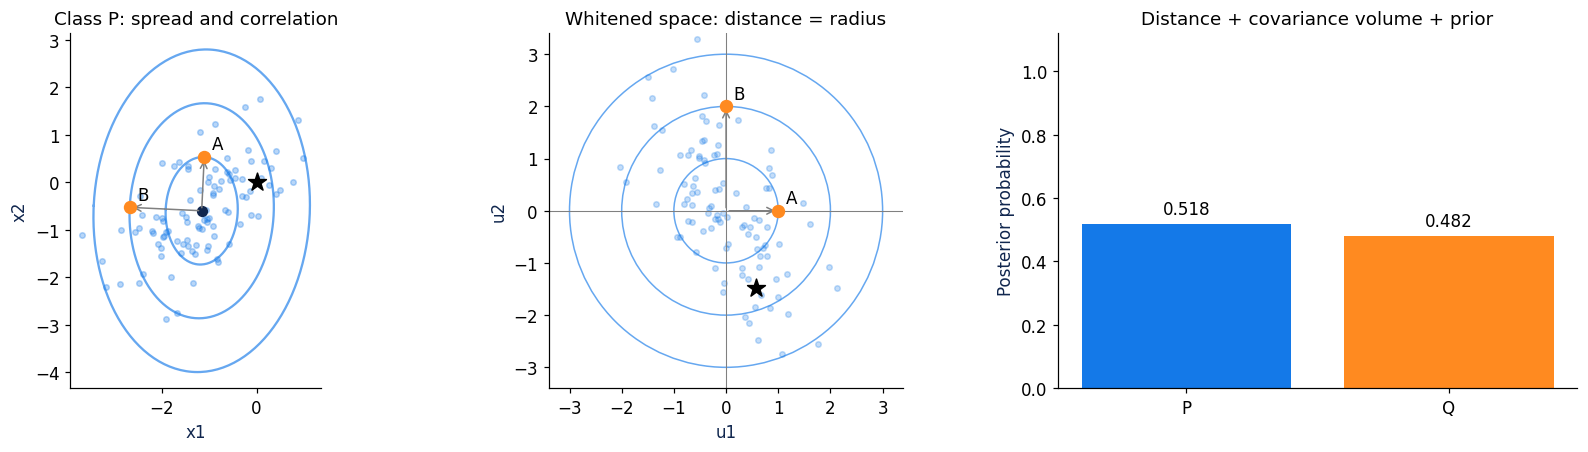

In [11]:
X_geo,y_geo,_,_,_,_=gaussian_data('Unequal covariance',100,.65)
geo_means=np.array([X_geo[y_geo==k].mean(axis=0) for k in [0,1]])
geo_covs=np.array([np.cov(X_geo[y_geo==k].T,bias=True) for k in [0,1]])
geo_priors=np.array([np.mean(y_geo==k) for k in [0,1]])
geo_shared=np.einsum('k,kij->ij',geo_priors,geo_covs)

def whitening(mu,S):
    lam,U=np.linalg.eigh(S);order=np.argsort(lam)[::-1];lam=lam[order];U=U[:,order]
    # Fix eigenvector signs so the displays have a consistent orientation.
    if U[0,0]<0:U[:,0]*=-1
    if U[1,1]<0:U[:,1]*=-1
    W=np.diag(1/np.sqrt(lam))@U.T
    return lam,U,W

def mahalanobis_squared(x,mu,S):
    d=x-mu
    return float(d@np.linalg.solve(S,d))

def geometry_view(ruler='Shared covariance (LDA)',selected_class='P',query_x1=0.,query_x2=0.):
    covs=np.repeat(geo_shared[None,:,:],2,axis=0) if ruler.startswith('Shared') else geo_covs
    k='PQ'.index(selected_class);mu=geo_means[k];S=covs[k]
    lam,U,W=whitening(mu,S)
    A=mu+U[:,0]*np.sqrt(lam[0]);B=mu+U[:,1]*np.sqrt(lam[1])*2
    q=np.array([query_x1,query_x2]);cloud=X_geo[y_geo==k]
    Z=(cloud-mu)@W.T;qa=W@(q-mu);aa=W@(A-mu);bb=W@(B-mu)
    d2=np.array([mahalanobis_squared(q,m,Sg) for m,Sg in zip(geo_means,covs)])
    score=-.5*(d2+np.linalg.slogdet(covs)[1])+np.log(geo_priors)
    post=np.exp(score-score.max());post/=post.sum()
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    axs[0].scatter(*cloud.T,c=COLORS[k],s=13,alpha=.3)
    for radius in [1,2,3]:axs[0].plot(*ellipse_points(mu,S,radius),c=BLUE,alpha=.65)
    for point,name in [(A,'A'),(B,'B')]:
        axs[0].annotate('',xy=point,xytext=mu,arrowprops={'arrowstyle':'->','color':'gray'})
        axs[0].scatter(*point,c=ORANGE,s=60,zorder=5);axs[0].annotate(name,point,xytext=(5,5),textcoords='offset points')
    axs[0].scatter(*mu,c=NAVY,s=40);axs[0].scatter(*q,c='black',marker='*',s=150,zorder=6)
    axs[0].set(xlabel='x1',ylabel='x2',title=f'Class {selected_class}: spread and correlation',aspect='equal')
    axs[1].scatter(*Z.T,c=COLORS[k],s=13,alpha=.25)
    for radius in [1,2,3]:axs[1].add_patch(plt.Circle((0,0),radius,fill=False,color=BLUE,alpha=.65))
    for point,name in [(aa,'A'),(bb,'B')]:
        axs[1].annotate('',xy=point,xytext=(0,0),arrowprops={'arrowstyle':'->','color':'gray'})
        axs[1].scatter(*point,c=ORANGE,s=60,zorder=5);axs[1].annotate(name,point,xytext=(5,5),textcoords='offset points')
    axs[1].scatter(*qa,c='black',marker='*',s=150,zorder=6)
    axs[1].axhline(0,c='gray',lw=.7);axs[1].axvline(0,c='gray',lw=.7)
    limit=max(3.4,np.abs(qa).max()+.4)
    axs[1].set(xlabel='u1',ylabel='u2',title='Whitened space: distance = radius',aspect='equal',xlim=(-limit,limit),ylim=(-limit,limit))
    axs[2].bar(['P','Q'],post,color=COLORS[:2])
    axs[2].set(ylim=(0,1.12),ylabel='Posterior probability',title='Distance + covariance volume + prior')
    for j in range(2):axs[2].text(j,post[j]+.03,f'{post[j]:.3f}',ha='center')
    plt.show()
    print('Query squared distances [P, Q]:',np.round(d2,4))
    print(f'Class {selected_class}: ||whitened query||^2={qa@qa:.4f}; original distance^2={d2[k]:.4f}')
    print('Reference A, B in whitened space:',np.round(aa,6),np.round(bb,6))
    # A common invertible standardization leaves the full-covariance distance unchanged.
    scale=X_geo.std(axis=0);Dinv=np.diag(1/scale)
    transformed=mahalanobis_squared(Dinv@q,Dinv@mu,Dinv@S@Dinv.T)
    print(f'After common axis scaling, distance^2={transformed:.4f} (unchanged)')

geometry_view()

Query squared distances [P, Q]: [2.5415 2.6862]
Class P: ||whitened query||^2=2.5415; original distance^2=2.5415
Reference A, B in whitened space: [ 1. -0.] [-0.  2.]
After common axis scaling, distance^2=2.5415 (unchanged)


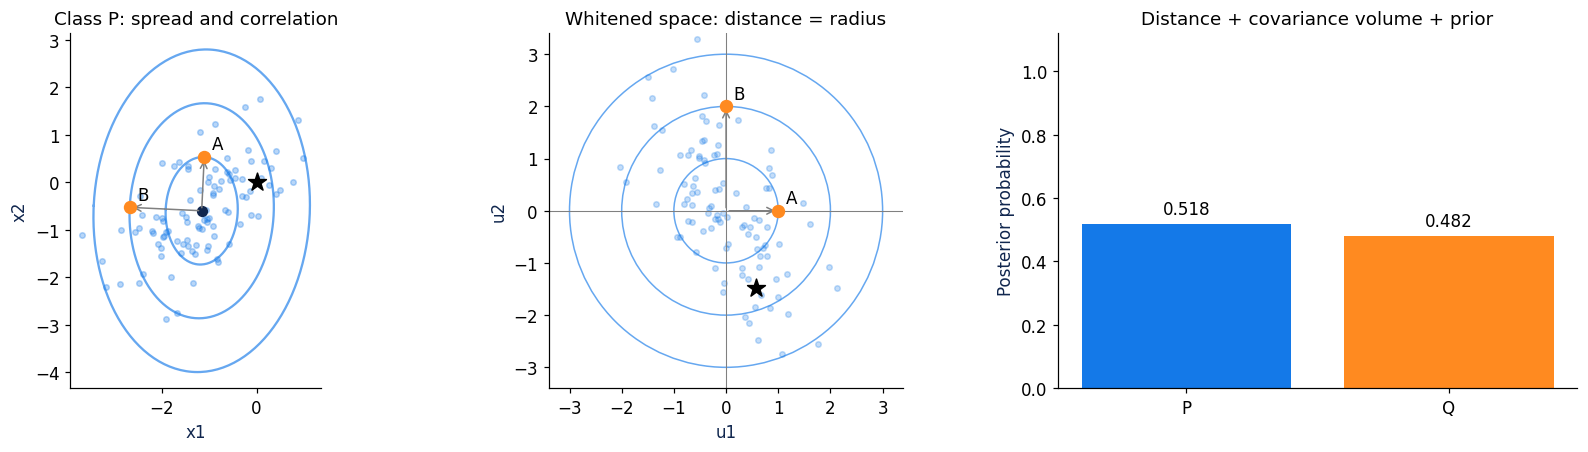

interactive(children=(Dropdown(description='Ruler', options=('Shared covariance (LDA)', 'Class covariance (QDA…

In [12]:
geometry_controls=controls(geometry_view,
    ruler=widgets.Dropdown(options=['Shared covariance (LDA)','Class covariance (QDA)'],description='Ruler',style={'description_width':'initial'}),
    selected_class=widgets.Dropdown(options=['P','Q'],description='Whiten class'),
    query_x1=slider(0,-4,4,.1,'Query x1'),query_x2=slider(0,-4,4,.1,'Query x2'))

## Check your understanding
1. Which covariance assumption distinguishes LDA from QDA?
2. Does per-feature standardization remove correlation?
3. Why can equal Euclidean distances correspond to different Mahalanobis distances?
4. Why is minimum Mahalanobis distance alone generally insufficient for Gaussian classification?
5. Why does common invertible feature scaling leave the exact full-covariance Mahalanobis distance unchanged?

**Documentation:** [LDA and QDA](https://scikit-learn.org/stable/modules/lda_qda.html),
[StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html),
[Mahalanobis distance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.mahalanobis.html).